In [2]:
import spacy
# Cargar modelo ahora en español 
try:
    nlp = spacy.load("es_core_news_sm")
except OSError:
    print("Descargando modelo...")
    from spacy.cli import download
    download("es_core_news_sm")
    nlp = spacy.load("es_core_news_sm")

# TEXTO DE ENTRADA 
with open("cap1_harry_potter.txt", "r", encoding="utf-8") as f:
    texto_principito = f.read()

# Ahora 'texto_principito' contiene todo el texto del archivo
print(f"Texto cargado con éxito. Longitud: {len(texto_principito)} caracteres.")

# 1. TOKENIZACIÓN
# SpaCy procesa el texto y crea el objeto 'doc' lleno de metadatos
doc = nlp(texto_principito)

# Mostrar los primeros 15 tokens para entender cómo "ve" la máquina el texto
print(f"--- 1. Tokenización (Total tokens: {len(doc)}) ---")
print([token.text for token in doc][:20]) 

Texto cargado con éxito. Longitud: 27573 caracteres.
--- 1. Tokenización (Total tokens: 5666) ---
['El', 'señor', 'y', 'la', 'señora', 'Dursley', ',', 'que', 'vivían', 'en', 'el', 'número', '4', 'de', 'Privet', 'Drive', ',', 'estaban', 'orgullosos', 'de']


In [3]:
# 2. FILTRADO DE STOP WORDS
# Separamos lo que aporta valor semántico del "pegamento" gramatical

tokens_relevantes = []
tokens_ruido = []

for token in doc:
    # Filtramos si es stopword o si es puntuación
    if not token.is_stop and not token.is_punct and token.text.strip():
        tokens_relevantes.append(token.text)
    elif token.is_stop:
        tokens_ruido.append(token.text)

print(f"\n--- 2. Filtrado de Stop Words ---")
print(f"Palabras eliminadas (Ruido): {tokens_ruido[:10]}...")
print(f"Palabras conservadas (Contenido): {tokens_relevantes[:10]}...")
print(f"Reducción de tamaño: de {len(doc)} a {len(tokens_relevantes)} tokens.")


--- 2. Filtrado de Stop Words ---
Palabras eliminadas (Ruido): ['El', 'y', 'la', 'que', 'en', 'el', 'de', 'estaban', 'de', 'decir']...
Palabras conservadas (Contenido): ['señor', 'señora', 'Dursley', 'vivían', 'número', '4', 'Privet', 'Drive', 'orgullosos', 'normales']...
Reducción de tamaño: de 5666 a 1936 tokens.


In [4]:
# 3. LEMATIZACIÓN Y NORMALIZACIÓN FINAL
# Reducimos las palabras a su raíz (Lema) y estandarizamos a minúsculas
# Objetivo: Que "hablo", "hablaré" y "habla" cuenten como el mismo concepto: "hablar"

tokens_normalizados = []
cambios_interesantes = []

for token in doc:
    # Aplicamos los mismos filtros de calidad que en el paso 2
    if not token.is_stop and not token.is_punct and token.text.strip():
        
        # AQUÍ OCURRE LA MAGIA: 
        # 1. Extraemos el lema (token.lemma_)
        # 2. Convertimos a minúsculas (.lower())
        lema = token.lemma_.lower()
        tokens_normalizados.append(lema)
        
        # Para fines educativos: Guardamos casos donde la palabra cambió drásticamente
        # Ej: "fui" -> "ir"
        if token.text.lower() != lema:
            cambios_interesantes.append(f"{token.text} ➡ {lema}")

print(f"\n--- 3. Lematización y Normalización ---")
print(f"Total de tokens procesados: {len(tokens_normalizados)}")
print(f"Ejemplos de transformaciones (Palabra original ➡ Lema):")
# Mostramos solo los primeros 5 cambios para no saturar la pantalla
print(cambios_interesantes[:10]) 

print(f"\nResultado final (Primeros 10 tokens):")
print(tokens_normalizados[:10])


--- 3. Lematización y Normalización ---
Total de tokens procesados: 1936
Ejemplos de transformaciones (Palabra original ➡ Lema):
['vivían ➡ vivir', 'orgullosos ➡ orgulloso', 'normales ➡ normal', 'personas ➡ persona', 'esperaría ➡ esperar', 'relacionadas ➡ relacionado', 'tales ➡ tal', 'tonterías ➡ tontería', 'llamada ➡ llamado', 'fabricaba ➡ fabricar']

Resultado final (Primeros 10 tokens):
['señor', 'señora', 'dursley', 'vivir', 'número', '4', 'privet', 'drive', 'orgulloso', 'normal']


In [5]:
import pandas as pd
from nltk.stem import SnowballStemmer

# Configuración del Stemmer (NLTK)
stemmer = SnowballStemmer("spanish")
# Comparativa lado a lado
data_comparativa = []

for token in doc:
    # Solo analizamos palabras, ignoramos puntuación y espacios para claridad
    if not token.is_punct and not token.is_space:
        
        # A. STEMMING (Corte de sufijos)
        raiz_stem = stemmer.stem(token.text)
        
        # B. LEMATIZACIÓN (Análisis morfológico de SpaCy)
        # Nota: SpaCy usa el contexto para saber si 'fui' es 'ir' o 'ser'
        lema = token.lemma_
        
        data_comparativa.append({
            "Original": token.text,
            "Stemming (Corte)": raiz_stem,
            "Lematización (Diccionario)": lema,
            "¿Coinciden?": raiz_stem == lema
        })

# Crear DataFrame para visualizar
df = pd.DataFrame(data_comparativa)

print(f"\n--- 3. Stemming vs Lematización ---")
# Mostramos palabras interesantes donde se vea la diferencia
# Buscamos verbos conjugados o plurales
palabras_interesantes = ["hombres", "olvidado", "eres", "domesticado", "invisible", "ojos"]
filtro = df[df["Original"].isin(palabras_interesantes)]

print(filtro.to_string(index=False))

print("\n--- Visualización completa de los primeros 10 tokens ---")
print(df.head(10).to_string(index=False))


--- 3. Stemming vs Lematización ---
Original Stemming (Corte) Lematización (Diccionario)  ¿Coinciden?
olvidado            olvid                    olvidar        False
    ojos             ojos                        ojo        False
    ojos             ojos                        ojo        False
    ojos             ojos                        ojo        False
    ojos             ojos                        ojo        False
    ojos             ojos                        ojo        False
    ojos             ojos                        ojo        False
    ojos             ojos                        ojo        False
    ojos             ojos                        ojo        False
    ojos             ojos                        ojo        False

--- Visualización completa de los primeros 10 tokens ---
Original Stemming (Corte) Lematización (Diccionario)  ¿Coinciden?
      El               el                         el         True
   señor            señor                      

In [4]:

# IMPORTACIÓN DE LIBRERÍAS
import spacy
import pandas as pd
import os

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report
from gensim.models import Word2Vec
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np

print("Librerías importadas correctamente.")


Librerías importadas correctamente.


In [5]:
# EXPORTACIÓN DEL TEXTO PROCESADO

texto_procesado = " ".join(tokens_normalizados)

with open("texto_procesado.txt", "w", encoding="utf-8") as archivo:
    archivo.write(texto_procesado)

print("Texto procesado guardado correctamente.")
print(f"Total de palabras: {len(tokens_normalizados)}")

NameError: name 'tokens_normalizados' is not defined

In [6]:
# PREPARACIÓN DEL CORPUS POR ORACIONES

corpus_oraciones = []

for oracion in doc.sents:

    tokens = [
        token.lemma_.lower()
        for token in oracion
        if not token.is_stop
        and not token.is_punct
        and not token.is_space
        and token.is_alpha
    ]

    if len(tokens) > 1:
        corpus_oraciones.append(tokens)

print(f"Total de oraciones procesadas: {len(corpus_oraciones)}")
print("\nPrimeras 5 oraciones:")
for oracion in corpus_oraciones[:5]:
    print(" ".join(oracion))

NameError: name 'doc' is not defined

In [7]:
# BAG OF WORDS

corpus_texto = [" ".join(oracion) for oracion in corpus_oraciones]

bow_vectorizer = CountVectorizer(max_features=40)
X_bow = bow_vectorizer.fit_transform(corpus_texto)

vocab_bow = bow_vectorizer.get_feature_names_out()

print("Matriz Bag of Words:", X_bow.shape)


# TF-IDF

tfidf_vectorizer = TfidfVectorizer(max_features=40)
X_tfidf = tfidf_vectorizer.fit_transform(corpus_texto)

vocab_tfidf = tfidf_vectorizer.get_feature_names_out()

print("Matriz TF-IDF:", X_tfidf.shape)

ValueError: empty vocabulary; perhaps the documents only contain stop words

In [8]:
# ENTRENAMIENTO WORD2VEC

modelo_word2vec = Word2Vec(
    sentences=corpus_oraciones,
    vector_size=100,
    window=5,
    min_count=1,
    workers=4,
    sg=1,
    epochs=100,
    seed=42
)

print("Modelo Word2Vec entrenado correctamente.")

print("\nTamaño del vocabulario:")
print(len(modelo_word2vec.wv))

# Consultar palabras similares
palabra = list(modelo_word2vec.wv.index_to_key)[0]

print(f"\nPalabra seleccionada: {palabra}")
print("Palabras similares:")
print(modelo_word2vec.wv.most_similar(palabra, topn=5))

RuntimeError: you must first build vocabulary before training the model

In [9]:
# FUNCIÓN PARA VISUALIZAR ESPACIOS VECTORIALES 3D

os.makedirs("graficas", exist_ok=True)

def graficar_espacio_3d(vectores, palabras, titulo, nombre_archivo):

    if len(palabras) < 3:
        print(f"No hay suficientes palabras para graficar {titulo}")
        return

    pca = PCA(n_components=3)
    coordenadas = pca.fit_transform(vectores)

    fig = plt.figure(figsize=(12, 8))
    ax = fig.add_subplot(111, projection="3d")

    ax.scatter(
        coordenadas[:, 0],
        coordenadas[:, 1],
        coordenadas[:, 2],
        s=55,
        alpha=0.8
    )

    for i, palabra in enumerate(palabras):
        ax.text(
            coordenadas[i, 0],
            coordenadas[i, 1],
            coordenadas[i, 2],
            palabra,
            fontsize=8
        )

    ax.set_title(titulo)
    ax.set_xlabel("Componente principal 1")
    ax.set_ylabel("Componente principal 2")
    ax.set_zlabel("Componente principal 3")

    plt.tight_layout()

    plt.savefig(
        f"graficas/{nombre_archivo}",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    print(f"Gráfica guardada: graficas/{nombre_archivo}")

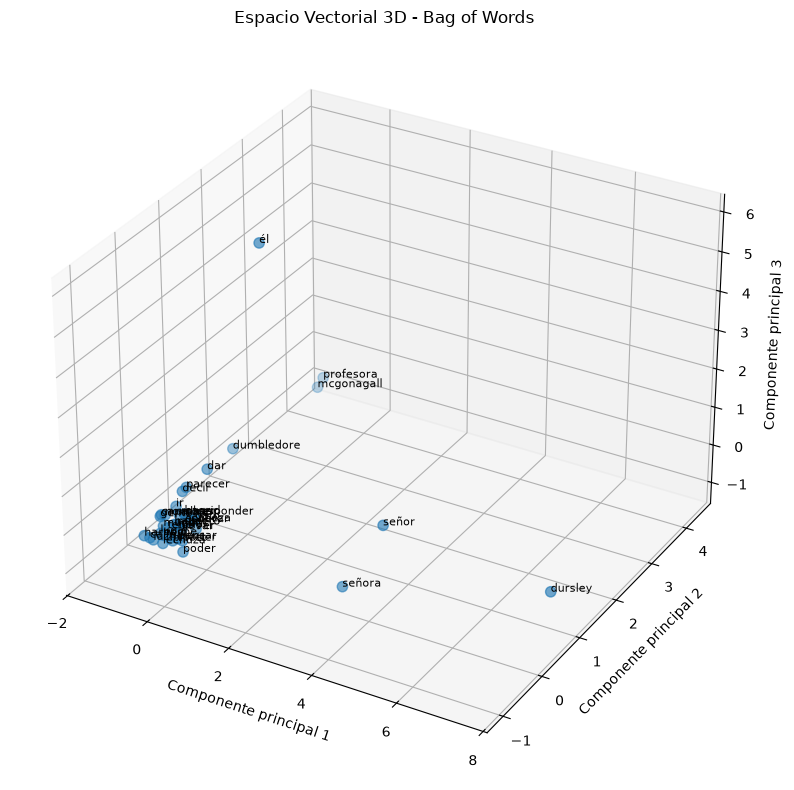

Gráfica guardada: graficas/01_bag_of_words.png


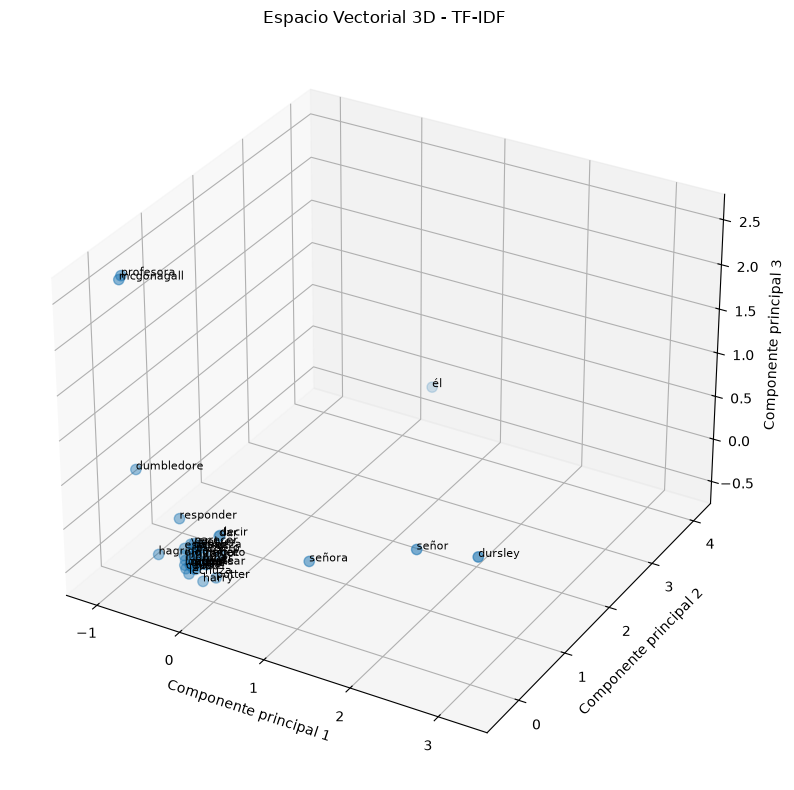

Gráfica guardada: graficas/02_tfidf.png


NameError: name 'np' is not defined

In [33]:
# A. BAG OF WORDS

matriz_bow_palabras = X_bow.T.toarray()

graficar_espacio_3d(
    matriz_bow_palabras,
    vocab_bow,
    "Espacio Vectorial 3D - Bag of Words",
    "01_bag_of_words.png"
)


# B. TF-IDF

matriz_tfidf_palabras = X_tfidf.T.toarray()

graficar_espacio_3d(
    matriz_tfidf_palabras,
    vocab_tfidf,
    "Espacio Vectorial 3D - TF-IDF",
    "02_tfidf.png"
)


# C. WORD2VEC

palabras_word2vec = modelo_word2vec.wv.index_to_key[:40]

vectores_word2vec = np.array([
    modelo_word2vec.wv[palabra]
    for palabra in palabras_word2vec
])

graficar_espacio_3d(
    vectores_word2vec,
    palabras_word2vec,
    "Espacio Vectorial 3D - Word2Vec",
    "03_word2vec.png"
)